# Multimodal Large Language Model (MLLM) Analysis for Pet Therapy Intervention (Study 2)

## Experimental Design & Alignment with Study 1 and Study 2
1. **Two Psychometric Components of State Anxiety (`STAI-AA` and `STAI-AP`)**:
   - In accordance with Study 1, the 20-item **Spielberger State-Trait Anxiety Inventory — State Anxiety Scale (`STAI-S`, Form Y-1, total score range 20–80)** is decomposed into two 10-item psychometric subscales:
     - **`STAI-AA` (Anxiety-Absent / Absence of Calmness & Security Subscale, range 10–40)**: Sum of 10 reverse-scored positively worded items (`Q3T1, 2, 5, 8, 10, 11, 15, 16, 19, 20`: feeling calm, secure, at ease, comfortable, relaxed, self-confident, satisfied, steady/composed). Higher `STAI-AA` indicates a greater absence of calmness and security (higher anxiety); lower `STAI-AA` indicates greater calmness, comfort, and security.
     - **`STAI-AP` (Anxiety-Present / Presence of Acute Tension Subscale, range 10–40)**: Sum of 10 directly scored negatively worded items (`Q3T3, 4, 6, 7, 9, 12, 13, 14, 17, 18`: feeling tense, strained, upset, frightened, nervous, jittery, indecisive, worried, confused/over-excited). Higher `STAI-AP` indicates greater acute somatic/autonomic tension and nervousness.
     - **Total State Anxiety (`STAI-Total`, range 20–80)**: $\text{STAI\_Total} = \text{STAI\_AA} + \text{STAI\_AP}$.

2. **Two-Step Independent Video Evaluation (`Pre` and `Post` Separately) Followed by Subtraction (`Pre - Post`)**:
   - Rather than uploading Pre-test and Post-test videos together in a single prompt, each recording is evaluated **independently** in two separate steps:
     - **Step 1 (`experiment_step="pre"`)**: Compress, upload, and predict `(stai_aa, stai_ap)` on the **Pre-test** video alone (`use_pre_and_post=False`).
     - **Step 2 (`experiment_step="post"`)**: Compress, upload, and predict `(stai_aa, stai_ap)` on the **Post-test** video alone (`use_pre_and_post=False`).
     - **Step 3 (`Pre - Post` Subtraction)**: Compute the state anxiety improvement by subtracting the Post-test prediction from the Pre-test prediction:
       $$\Delta\text{STAI\_AA} = \text{STAI\_AA}_{\text{pre}} - \text{STAI\_AA}_{\text{post}}, \quad \Delta\text{STAI\_AP} = \text{STAI\_AP}_{\text{pre}} - \text{STAI\_AP}_{\text{post}}, \quad \Delta\text{STAI\_Total} = \text{STAI\_Total}_{\text{pre}} - \text{STAI\_Total}_{\text{post}}$$
       matching Study 1's exact definition ($\text{Improvement} = \text{Pre} - \text{Post}$, where positive values indicate anxiety reduction).
     - **Step 4 (Print Out & Evaluate Results)**: Evaluate Pre-test, Post-test, and subtracted Improvement (`Pre - Post`) predictions against ground-truth psychometric scores.

3. **Three Modality Ablation Experiments**:
   - **Experiment 1 — Video Baseline (`Video Only`)**: Uses raw silent video (`video_only=True`); prompt restricts analysis strictly to image-based visual information.
   - **Experiment 2 — Video + Audio (`Non-Semantic Vocal Acoustics Only`)**: Uses audio-merged video (`video_only=False`); prompt strictly prohibits using the semantic meaning of spoken words and restricts audio analysis to non-semantic vocal acoustics (pitch/F0, tone, vocal jitter/shimmer, intensity, speech rate, pauses, breathing).
   - **Experiment 3 — Video + Audio + Speech Context (`Full Audiovisual + Speech Semantics`)**: Uses audio-merged video (`video_only=False`); prompt integrates visual cues, vocal acoustics, and the semantic meaning of the participant's spoken response.

# Environment
## Packages and Settings

In [ ]:
import sys, os, importlib
for _dir in [os.path.abspath("utilities"), os.path.abspath("../utilities"), os.path.abspath("env/configs"), os.path.abspath("../env/configs")]:
    if os.path.exists(_dir) and _dir not in sys.path:
        sys.path.insert(0, _dir)

for _mod_name in ["video_helper", "local_data_loader", "experiment_helper", "data_analysis_helper", "configs"]:
    if _mod_name in sys.modules:
        importlib.reload(sys.modules[_mod_name])

from configs import *

# Load the 92 participants in the Study 2 joint multimodal prediction scope (specified_avrr92)
df_participants, df_features, df_fdef = data_loader.load_participants_and_features(only_prediction_scope=True)
list_users = df_participants["user_id"].tolist()
group_names = {1: "COMB", 2: "PET", 3: "FEED", 4: "OBS"}

# Number of participants to test during Trial Runs (for debugging before full 92-participant runs)
n_trial_users = 2
trial_users = list_users[:n_trial_users]

run_trial = False
run_experiments = False
print(f"Loaded {len(list_users)} participants in prediction scope (specified_avrr92).")
print(f"Trial run subset ({len(trial_users)} participants): {trial_users}")
display(df_participants[[
    "participant_id", "condition", "Group Name", "Petting", "Feeding",
    "STAI_AA_pre", "STAI_AA_post", "STAI_AA_improvement",
    "STAI_AP_pre", "STAI_AP_post", "STAI_AP_improvement",
    "STAI_pre", "STAI_post", "STAI_improvement"
]].head())

Loaded 92 participants in prediction scope (specified_avrr92).
Trial run subset (2 participants): [4, 5]


,participant_id,condition,Group Name,Petting,Feeding,STAI_AA_pre,STAI_AA_post,STAI_AA_improvement,STAI_AP_pre,STAI_AP_post,STAI_AP_improvement,STAI_pre,STAI_post,STAI_improvement
0,004,combined,COMB,1,1,20,13,7,15,15,0,35,28,7
1,005,petting,PET,1,0,27,23,4,13,11,2,40,34,6
2,008,feeding,FEED,0,1,15,21,-6,19,13,6,34,34,0
3,011,combined,COMB,1,1,29,21,8,16,14,2,45,35,10
4,012,petting,PET,1,0,14,12,2,13,10,3,27,22,5


## Template

In [11]:
part_first_image_only = """

The attached video is a recording captured during a psychological experiment investigating human-animal interaction and stress recovery.

The individual located at the center of the frame is the primary participant and the only subject to be analyzed.

You must make a clear and definite judgment on the two core psychometric components of the Spielberger State-Trait Anxiety Inventory — State Anxiety Scale (STAI-S).

IMPORTANT: You should only use image-based visual information. You must not analyze, infer, or use the semantic content of the participant's speech nor any non-semantic acoustic features (e.g., tone, pitch, intensity, rhythm). Consider only the image-based visual information from the video frames.

This constraint is strict and non-negotiable.

"""

part_first_no_speech_text = """

The attached video is a recording captured during a psychological experiment investigating human-animal interaction and stress recovery.

The individual located at the center of the frame is the primary participant and the only subject to be analyzed.

You must make a clear and definite judgment on the two core psychometric components of the Spielberger State-Trait Anxiety Inventory — State Anxiety Scale (STAI-S).

IMPORTANT: You must not analyze, transcribe, infer, or use the semantic meaning of the participant's spoken words under any circumstances. Only visual cues and non-semantic acoustic features (e.g., vocal tone, fundamental frequency/pitch, vocal stability/jitter/shimmer, intensity, speech rate, pauses, and breathing rhythm) may be considered.

This constraint is strict and non-negotiable.

"""

part_first_part_with_video = """

The attached video is a recording captured during a psychological experiment investigating human-animal interaction and stress recovery.

The individual located at the center of the frame is the primary participant and the only subject to be analyzed. No other individuals should be considered.

You must provide a clear, unambiguous, and definite judgment on the two core psychometric components of the Spielberger State-Trait Anxiety Inventory — State Anxiety Scale (STAI-S), integrating visual behavior, non-semantic vocal acoustics, and the semantic meaning of the participant's spoken words. Uncertainty or vague responses are not allowed.

"""

part_main = """
A numeric score is required for each of the two STAI-S psychometric dimensions in all cases.

=== Explanation of the STAI-S and Its Two Core Psychometric Components ===

The Spielberger State-Trait Anxiety Inventory — State Anxiety Scale (STAI-S, Form Y-1) is a standard 20-item psychological assessment measuring a person's momentary state anxiety. Each of the 20 items is rated on a 4-point scale (1 = Not at all, 2 = Somewhat, 3 = Moderately so, 4 = Very much so), yielding a Total State Anxiety score ranging from 20 to 80.
Psychometric factor analysis and Study 1 of this research divide the 20-item STAI-S into two distinct 10-item subscales (each scored as an integer from 10 to 40, such that STAI_Total = STAI_AA + STAI_AP):

1. stai_aa — STAI Anxiety-Absent Subscale (Absence of Calmness & Security; 10 items, integer range 10 to 40):
   * Psychometric Definition: Sum of 10 reverse-scored positively worded items measuring the absence of calmness, comfort, and psychological security (reverse-scored items for feeling calm, secure, at ease, comfortable, relaxed, self-confident, satisfied, content, steady, and composed).
   * Score Interpretation (10 to 40):
     - 10–16: Very high calmness, warmth, comfort, and psychological security (minimal absence of calmness).
     - 17–24: Moderate or typical baseline level of calmness and comfort.
     - 25–40: Severe absence of calmness and security; the participant appears emotionally guarded, depleted of positive ease, or unable to relax.
   * Observable Multimodal Indicators for stai_aa:
     - Visual cues: Genuine warm smiling (Duchenne smiles with cheek raising and orbicularis oculi engagement), relaxed forehead and periorbital muscles, open and comfortable posture, and smooth natural movement indicate high calmness (lower stai_aa score, 10–18). Flat or guarded affect, lack of warm facial expression, and stiff posture indicate an absence of calmness (higher stai_aa score, 22–40).
     - Non-semantic vocal acoustic cues (when audio is permitted): Warm, resonant vocal timbre, smooth prosodic flow, and relaxed breathing indicate lower stai_aa; flat, constricted, or unrelaxed vocal tone indicates higher stai_aa.
     - Verbal semantic cues (ONLY when speech text meaning is permitted): Expressing feelings of comfort, relaxation, warmth, enjoyment, or feeling safe and settled indicates lower stai_aa; expressing an inability to relax, emotional detachment, or lack of ease indicates higher stai_aa.

2. stai_ap — STAI Anxiety-Present Subscale (Presence of Acute Tension; 10 items, integer range 10 to 40):
   * Psychometric Definition: Sum of 10 directly scored negatively worded items measuring the active presence of acute somatic and cognitive tension (items for feeling tense, strained, upset, frightened, nervous, jittery, indecisive, worried, confused, and over-excited).
   * Score Interpretation (10 to 40):
     - 10–14: Minimal acute tension or nervousness (calm somatic/autonomic state).
     - 15–22: Mild-to-moderate acute tension, strain, or nervousness.
     - 23–40: High acute tension, pronounced nervousness, worry, or somatic agitation.
   * Observable Multimodal Indicators for stai_ap:
     - Visual cues: Furrowed brow, eyelid tightening, lip pressing or biting, frequent blinking, gaze aversion, restless fidgeting, self-adaptors, or rigid facial tension indicate higher stai_ap (20–40); relaxed facial musculature and steady gaze indicate lower stai_ap (10–15).
     - Non-semantic vocal acoustic cues (when audio is permitted): Elevated fundamental frequency (pitch/F0), increased vocal jitter or shimmer, shaky or strained voice, frequent hesitations, rapid or irregular speech rate, and tense audible sighs indicate higher stai_ap.
     - Verbal semantic cues (ONLY when speech text meaning is permitted): Explicitly mentioning feeling nervous, stressed, worried, pressured, tense, or uneasy indicates higher stai_ap.

You may use the following extra information if provided:

=== Extra Information ===

[[COT]]
[[KNOWLEDGE]]
[[TOOLS]]

=== Scoring Rules (Mandatory) ===

* Assign an integer score from 10 to 40 for `stai_aa` (STAI Anxiety-Absent / Absence of Calmness & Security Subscale).
* Assign an integer score from 10 to 40 for `stai_ap` (STAI Anxiety-Present / Presence of Acute Tension Subscale).
* You must output an integer score for both `stai_aa` and `stai_ap` in every case.
* Do not leave any field blank. Do not omit any score.

=== Output Format (Strict) ===

Output exactly in the following format:

(stai_aa, stai_ap) = (X, Y)

Z

"""

last_part = """
Where:

X is an integer from 10 to 40 representing `stai_aa` (Absence of Calmness & Security Subscale; higher = less calm / more anxious).

Y is an integer from 10 to 40 representing `stai_ap` (Presence of Acute Tension Subscale; higher = more tense / more anxious).

Z is a concise explanation supporting the assigned scores.

=== Hard Constraints ===

* Analyze only the primary participant.
* Do not reference or repeat the prompt.
* If no video file is attached, return exactly:
  (stai_aa, stai_ap) = (-1, -1)
* Respond in English only.
* Ensure the output format is strictly followed.

"""

template_video_only = part_first_image_only + part_main + last_part
template_no_speech_text = part_first_no_speech_text + part_main + last_part
template_with_speech_text = part_first_part_with_video + part_main + last_part

# Trial Run (Pilot Debugging Before All Formal Executions)
Runs a quick end-to-end 4-step pilot check on `trial_users` (default: the first 2 participants, `004` and `005`) **before** launching the full 92-participant formal experiments.
This trial run verifies:
1. **Archive Extraction & Audio-Video Merging**: Confirms raw `.mp4` and `.wav` files are extracted and merged into `video_with_audio/`.
2. **FFmpeg Video Compression**: Automatically selects and caches a working FFmpeg encoder (`libx265`, `libx264`, `libopenh264`, or `mpeg4`) and verifies compressed file sizes.
3. **Gemini File API Upload**: Confirms each compressed video is uploaded with a valid active URI (`1 video(s)` attached, preventing empty `0-video` calls).
4. **Two-Step Independent Prediction (`Pre` and `Post`) & Subtraction (`Pre - Post`)**: Confirms the MLLM outputs valid `(stai_aa, stai_ap)` integer scores in `[10, 40]` for both Pre-test and Post-test, and computes `Improvement = Pre - Post`.

In [12]:
# Trial Step 1 & Step 2: Test Pre-Test and Post-Test Video Compression, Upload, and MLLM Prediction on `trial_users`
trial_helper_pre = experiment_helper.copy()
trial_helper_pre.define_experiment(
    participant_sn_range=trial_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "trial_merged_video_pre.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_trial_exp3_pre.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="pre",
    video_only=False,
    use_pre_and_post=False,
    template_main=template_with_speech_text,
)

trial_helper_post = experiment_helper.copy()
trial_helper_post.define_experiment(
    participant_sn_range=trial_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "trial_merged_video_post.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_trial_exp3_post.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="post",
    video_only=False,
    use_pre_and_post=False,
    template_main=template_with_speech_text,
)

if run_trial:
    df_trial_pre = trial_helper_pre.run_trial_before_formal(n_trial=len(trial_users), over_ride_existing=True, verbose=True)
    df_trial_post = trial_helper_post.run_trial_before_formal(n_trial=len(trial_users), over_ride_existing=True, verbose=True)
    df_trial_diff = trial_helper_post.compute_pre_post_difference(
        df_pre=df_trial_pre,
        df_post=df_trial_post,
        path_pickle_diff=os.path.join(path_paper, "temp", "pickle", "df_trial_exp3_diff.plk"),
    )
    with pd.option_context("display.max_colwidth", None):
        display(df_trial_diff[[
            "Group Name", "Participant SN",
            "STAI_AA_pre", "stai_aa_pre_pred", "STAI_AA_post", "stai_aa_post_pred", "STAI_AA_improvement", "stai_aa_imp_pred",
            "STAI_AP_pre", "stai_ap_pre_pred", "STAI_AP_post", "stai_ap_post_pred", "STAI_AP_improvement", "stai_ap_imp_pred",
            "STAI_improvement", "stai_total_imp_pred",
            "explanation_pre", "explanation_post"
        ]])

[INFO] Pickle file exists; reading it directly: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/trial_merged_video_pre.plk
[INFO] Pickle file exists; reading it directly: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/trial_merged_video_post.plk


# Experiment 1 - Video Baseline (`Video Only`, No Audio)
Evaluates Pre-test and Post-test videos independently using **image-based visual information only (`video_only=True`)**, then subtracts Post-test predictions from Pre-test predictions ($\text{Improvement} = \text{Pre} - \text{Post}$).

## Step 1: Pre-Test Video Definition, Trial Check & Formal Prediction (`experiment_step="pre"`)

In [13]:
experiment_helper_1_pre = experiment_helper.copy()
experiment_helper_1_pre.define_experiment(
    participant_sn_range=list_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "video_pre.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_experiment_1_pre.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="pre",
    video_only=True,
    use_pre_and_post=False,
    template_main=template_video_only,
    interpreters=[],
    template_cot="",
    template_knowledge_injection="",
    template_tools="",
)
df_video_1_pre = experiment_helper_1_pre.get_df_video_path()
display(df_video_1_pre.head())

[INFO] Pickle file exists; reading it directly: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/video_pre.plk


,Experiment Name,Participant SN,Experiment Step,Pre Video Path,Post Video Path,Video Path,Pre Audio Path,Post Audio Path,Pre Merged File Path,Post Merged File Path,...,STAI_AP_pre,STAI_AP_post,STAI_AP_improvement,in_prediction_scope,uploaded_file_pre_video_only,uploaded_file_video_only,uploaded_file_pre_video_merged,uploaded_file_video_merged,Pre Compressed Video Path,Compressed Video Path
0,PS-035,004,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,,...,15,15,0,True,None,name='files/60x5mn7h6h0a' display_name=None mi...,None,None,None,/mnt/c/Working/google/Programming/Python/wsl3/...
1,PS-035,005,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,,...,13,11,2,True,None,None,None,None,None,None
2,PS-035,008,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,,...,19,13,6,True,None,None,None,None,None,None
3,PS-035,011,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,,...,16,14,2,True,None,None,None,None,None,None
4,PS-035,012,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,,...,13,10,3,True,None,None,None,None,None,None


In [14]:
# [Trial Check Before Formal Step 1] Test on 1 participant first to verify compression, upload, and score parsing
if run_trial:
    df_trial_1_pre = experiment_helper_1_pre.run_trial_before_formal(n_trial=1, over_ride_existing=False, verbose=True)
    display(df_trial_1_pre[["Participant SN", "Group Name", "STAI_AA_pre", "stai_aa", "STAI_AP_pre", "stai_ap", "STAI_pre", "stai_total", "explanation"]])

In [15]:
# [Formal Execution — Experiment 1 Step 1 (All 92 Participants, Pre-Test)]
run_experiments = True

if run_experiments:
    df_result_1_pre = experiment_helper_1_pre.run_exp_pet_therapy(over_ride_existing=False, max_workers=4)
else:
    df_result_1_pre = experiment_helper_1_pre.get_df_experiment_results()

=== run_exp_pet_therapy (PRE) start ===
[Participant 004 - PRE] Video already uploaded and active.
[FFmpeg] Selected working encoder: /usr/bin/ffmpeg [libx265 -crf 32]
Compression complete (/usr/bin/ffmpeg [libx265 -crf 32]) -> /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/011_pre_compressed.mp4
[Participant 011 - PRE] 3.17 MB -> 0.40 MB (011_pre_compressed.mp4)
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/011_pre_compressed.mp4 開始上傳...
Compression complete (/usr/bin/ffmpeg [libx265 -crf 32]) -> /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/005_pre_compressed.mp4
[Participant 005 - PRE] 3.84 MB -> 0.48 MB (005_pre_compressed.mp4)
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/005_pre_com

## Step 2: Post-Test Video Definition, Trial Check & Formal Prediction (`experiment_step="post"`)

In [16]:
experiment_helper_1_post = experiment_helper.copy()
experiment_helper_1_post.define_experiment(
    participant_sn_range=list_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "video_post.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_experiment_1_post.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="post",
    video_only=True,
    use_pre_and_post=False,
    template_main=template_video_only,
    interpreters=[],
    template_cot="",
    template_knowledge_injection="",
    template_tools="",
)
df_video_1_post = experiment_helper_1_post.get_df_video_path()
display(df_video_1_post.head())

[INFO] Video metadata saved to pickle: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/video_post.plk


,Experiment Name,Participant SN,Experiment Step,Pre Video Path,Post Video Path,Video Path,Pre Audio Path,Post Audio Path,Pre Merged File Path,Post Merged File Path,...,STAI_pre,STAI_post,STAI_improvement,STAI_AA_pre,STAI_AA_post,STAI_AA_improvement,STAI_AP_pre,STAI_AP_post,STAI_AP_improvement,in_prediction_scope
0,PS-035,004,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,35,28,7,20,13,7,15,15,0,True
1,PS-035,005,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,40,34,6,27,23,4,13,11,2,True
2,PS-035,008,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,34,34,0,15,21,-6,19,13,6,True
3,PS-035,011,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,45,35,10,29,21,8,16,14,2,True
4,PS-035,012,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,27,22,5,14,12,2,13,10,3,True


In [17]:
# [Trial Check Before Formal Step 2] Test on 1 participant first to verify compression, upload, and score parsing
if run_trial:
    df_trial_1_post = experiment_helper_1_post.run_trial_before_formal(n_trial=1, over_ride_existing=False, verbose=True)
    display(df_trial_1_post[["Participant SN", "Group Name", "STAI_AA_post", "stai_aa", "STAI_AP_post", "stai_ap", "STAI_post", "stai_total", "explanation"]])

In [18]:
# [Formal Execution — Experiment 1 Step 2 (All 92 Participants, Post-Test)]
if run_experiments:
    df_result_1_post = experiment_helper_1_post.run_exp_pet_therapy(over_ride_existing=False, max_workers=4)
else:
    df_result_1_post = experiment_helper_1_post.get_df_experiment_results()

=== run_exp_pet_therapy (POST) start ===
Compression complete (/usr/bin/ffmpeg [libx265 -crf 32]) -> /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/004_post_compressed.mp4
[Participant 004 - POST] 2.34 MB -> 0.25 MB (004_post_compressed.mp4)
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/004_post_compressed.mp4 開始上傳...
Compression complete (/usr/bin/ffmpeg [libx265 -crf 32]) -> /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/005_post_compressed.mp4
[Participant 005 - POST] 3.57 MB -> 0.37 MB (005_post_compressed.mp4)
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/005_post_compressed.mp4 開始上傳...
Compression complete (/usr/bin/ffmpeg [libx265 -crf 32]) -> /mnt/c/Working/google/Programming/Pytho

## Step 3: Subtract Pre-Test and Post-Test Predictions (`Improvement = Pre - Post`)

In [20]:
df_result_1_diff = experiment_helper_1_post.compute_pre_post_difference(
    df_pre=df_result_1_pre,
    df_post=df_result_1_post,
    path_pickle_diff=os.path.join(path_paper, "temp", "pickle", "df_experiment_1_diff.plk"),
)
df_result_1_diff.to_csv("df_results_exp_1_diff.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(df_result_1_diff[[
        "Group Name", "Participant SN",
        "STAI_AA_pre", "stai_aa_pre_pred", "STAI_AA_post", "stai_aa_post_pred", "STAI_AA_improvement", "stai_aa_imp_pred",
        "STAI_AP_pre", "stai_ap_pre_pred", "STAI_AP_post", "stai_ap_post_pred", "STAI_AP_improvement", "stai_ap_imp_pred",
        "STAI_improvement", "stai_total_imp_pred",
    ]].head(10))

[INFO] Subtracted Pre-Post difference DataFrame saved to: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/df_experiment_1_diff.plk


,Group Name,Participant SN,STAI_AA_pre,stai_aa_pre_pred,STAI_AA_post,stai_aa_post_pred,STAI_AA_improvement,stai_aa_imp_pred,STAI_AP_pre,stai_ap_pre_pred,STAI_AP_post,stai_ap_post_pred,STAI_AP_improvement,stai_ap_imp_pred,STAI_improvement,stai_total_imp_pred
0,COMB,004,20,18.0,13,17.0,7,1.0,15,16.0,15,14.0,0,2.0,7,3.0
1,PET,005,27,16.0,23,16.0,4,0.0,13,15.0,11,15.0,2,0.0,6,0.0
2,FEED,008,15,18.0,21,15.0,-6,3.0,19,14.0,13,13.0,6,1.0,0,4.0
3,COMB,011,29,18.0,21,18.0,8,0.0,16,15.0,14,14.0,2,1.0,10,1.0
4,PET,012,14,18.0,12,18.0,2,0.0,13,16.0,10,16.0,3,0.0,5,0.0
5,COMB,017,13,18.0,10,18.0,3,0.0,11,16.0,10,16.0,1,0.0,4,0.0
6,FEED,019,23,24.0,20,16.0,3,8.0,11,21.0,10,12.0,1,9.0,4,17.0
7,PET,022,11,18.0,12,18.0,-1,0.0,15,14.0,21,16.0,-6,-2.0,-7,-2.0
8,COMB,024,21,24.0,21,18.0,0,6.0,12,23.0,11,14.0,1,9.0,1,15.0
9,FEED,025,35,14.0,21,15.0,14,-1.0,25,12.0,19,12.0,6,0.0,20,-1.0


## Step 4: Print Out Results (Experiment 1 — Video Baseline)

=== Exp 1. Video Baseline (Pre - Post) Evaluation ===
STAI-AA component threshold (mean): 0.978
STAI-AP component threshold (mean): 1.130

[STAI Two-Component & Total Psychometric Regression (Exp 1. Video Baseline (Pre - Post))]:
  Pre-Test  | STAI-AA (Calmness/Security Absence, 10-40) (n=92): MAE=5.511, RMSE=6.956, R²=-0.359, Pearson r=0.141 (p=0.1788), Spearman ρ=0.134 (p=0.2045)
  Pre-Test  | STAI-AP (Acute Tension Presence, 10-40)    (n=92): MAE=4.163, RMSE=5.644, R²=-0.249, Pearson r=0.022 (p=0.8363), Spearman ρ=-0.039 (p=0.7089)
  Pre-Test  | STAI-Total (State Anxiety Total, 20-80)    (n=92): MAE=8.217, RMSE=10.735, R²=-0.301, Pearson r=0.125 (p=0.2358), Spearman ρ=0.128 (p=0.2225)
  Post-Test | STAI-AA (Calmness/Security Absence, 10-40) (n=92): MAE=5.250, RMSE=6.387, R²=-0.391, Pearson r=-0.050 (p=0.6340), Spearman ρ=-0.029 (p=0.7860)
  Post-Test | STAI-AP (Acute Tension Presence, 10-40)    (n=92): MAE=3.576, RMSE=4.992, R²=-0.369, Pearson r=0.063 (p=0.5522), Spearman ρ=0.020 (p

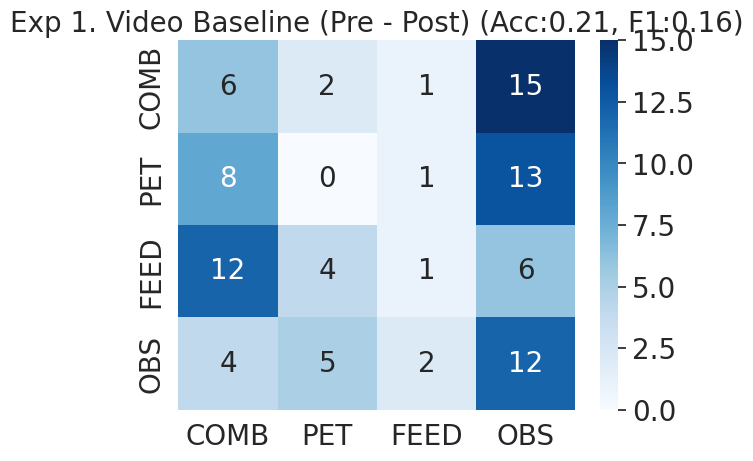

In [21]:
df_eval_1 = data_analysis_helper.merge_and_show_accuracy(
    df_list=[df_result_1_diff],
    threshold_type="mean",
    chart_helper=chart_helper,
    title="Exp 1. Video Baseline (Pre - Post)",
    font_size=20,
)

# Experiment 2 - Video + Audio (`Non-Semantic Vocal Acoustics Only`, No Speech Text Meaning)
Evaluates Pre-test and Post-test audio-merged videos independently (`video_only=False`) while **strictly prohibiting any use of the semantic meaning of the participant's spoken words**, then subtracts Post-test predictions from Pre-test predictions ($\text{Improvement} = \text{Pre} - \text{Post}$).

## Step 1: Pre-Test Video Definition, Trial Check & Formal Prediction (`experiment_step="pre"`)

In [22]:
experiment_helper_2_pre = experiment_helper.copy()
experiment_helper_2_pre.define_experiment(
    participant_sn_range=list_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "merged_video_pre.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_experiment_2_pre.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="pre",
    video_only=False,
    use_pre_and_post=False,
    interpreters=[],
    template_main=template_no_speech_text,
    template_cot="",
    template_knowledge_injection="",
    template_tools="",
)
df_video_2_pre = experiment_helper_2_pre.get_df_video_path()
display(df_video_2_pre.head())

[INFO] Video metadata saved to pickle: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/merged_video_pre.plk


,Experiment Name,Participant SN,Experiment Step,Pre Video Path,Post Video Path,Video Path,Pre Audio Path,Post Audio Path,Pre Merged File Path,Post Merged File Path,...,STAI_pre,STAI_post,STAI_improvement,STAI_AA_pre,STAI_AA_post,STAI_AA_improvement,STAI_AP_pre,STAI_AP_post,STAI_AP_improvement,in_prediction_scope
0,PS-035,004,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,35,28,7,20,13,7,15,15,0,True
1,PS-035,005,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,40,34,6,27,23,4,13,11,2,True
2,PS-035,008,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,34,34,0,15,21,-6,19,13,6,True
3,PS-035,011,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,45,35,10,29,21,8,16,14,2,True
4,PS-035,012,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,27,22,5,14,12,2,13,10,3,True


In [23]:
# [Trial Check Before Formal Step 1] Test on 1 participant first to verify audio-merged compression, upload, and score parsing
if run_trial:
    df_trial_2_pre = experiment_helper_2_pre.run_trial_before_formal(n_trial=1, over_ride_existing=False, verbose=True)
    display(df_trial_2_pre[["Participant SN", "Group Name", "STAI_AA_pre", "stai_aa", "STAI_AP_pre", "stai_ap", "STAI_pre", "stai_total", "explanation"]])

In [24]:
# [Formal Execution — Experiment 2 Step 1 (All 92 Participants, Pre-Test)]
if run_experiments:
    df_result_2_pre = experiment_helper_2_pre.run_exp_pet_therapy(over_ride_existing=False, max_workers=4)
else:
    df_result_2_pre = experiment_helper_2_pre.get_df_experiment_results()

=== run_exp_pet_therapy (PRE) start ===
[Participant 004 - PRE] 2.31 MB -> 0.76 MB (004_pre_merged_compressed.mp4)
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/004_pre_merged_compressed.mp4 開始上傳...
[Participant 005 - PRE] 4.57 MB -> 1.50 MB (005_pre_merged_compressed.mp4)
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/005_pre_merged_compressed.mp4 開始上傳...
Compression complete (/usr/bin/ffmpeg [libx265 -crf 32]) -> /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/011_pre_merged_compressed.mp4
[Participant 011 - PRE] 3.81 MB -> 1.28 MB (011_pre_merged_compressed.mp4)
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/011_pre_merged_compressed.mp4 開始上傳...
Compression complete (/usr/bin/ffmpeg [libx

## Step 2: Post-Test Video Definition, Trial Check & Formal Prediction (`experiment_step="post"`)

In [25]:
experiment_helper_2_post = experiment_helper.copy()
experiment_helper_2_post.define_experiment(
    participant_sn_range=list_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "merged_video_post.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_experiment_2_post.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="post",
    video_only=False,
    use_pre_and_post=False,
    interpreters=[],
    template_main=template_no_speech_text,
    template_cot="",
    template_knowledge_injection="",
    template_tools="",
)
df_video_2_post = experiment_helper_2_post.get_df_video_path()
display(df_video_2_post.head())

[INFO] Video metadata saved to pickle: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/merged_video_post.plk


,Experiment Name,Participant SN,Experiment Step,Pre Video Path,Post Video Path,Video Path,Pre Audio Path,Post Audio Path,Pre Merged File Path,Post Merged File Path,...,STAI_pre,STAI_post,STAI_improvement,STAI_AA_pre,STAI_AA_post,STAI_AA_improvement,STAI_AP_pre,STAI_AP_post,STAI_AP_improvement,in_prediction_scope
0,PS-035,004,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,35,28,7,20,13,7,15,15,0,True
1,PS-035,005,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,40,34,6,27,23,4,13,11,2,True
2,PS-035,008,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,34,34,0,15,21,-6,19,13,6,True
3,PS-035,011,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,45,35,10,29,21,8,16,14,2,True
4,PS-035,012,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,27,22,5,14,12,2,13,10,3,True


In [26]:
# [Trial Check Before Formal Step 2] Test on 1 participant first to verify audio-merged compression, upload, and score parsing
if run_trial:
    df_trial_2_post = experiment_helper_2_post.run_trial_before_formal(n_trial=1, over_ride_existing=False, verbose=True)
    display(df_trial_2_post[["Participant SN", "Group Name", "STAI_AA_post", "stai_aa", "STAI_AP_post", "stai_ap", "STAI_post", "stai_total", "explanation"]])

In [27]:
# [Formal Execution — Experiment 2 Step 2 (All 92 Participants, Post-Test)]
if run_experiments:
    df_result_2_post = experiment_helper_2_post.run_exp_pet_therapy(over_ride_existing=False, max_workers=4)
else:
    df_result_2_post = experiment_helper_2_post.get_df_experiment_results()

=== run_exp_pet_therapy (POST) start ===
[Participant 005 - POST] 4.13 MB -> 1.14 MB (005_post_merged_compressed.mp4)
[Participant 004 - POST] 2.70 MB -> 0.73 MB (004_post_merged_compressed.mp4)
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/005_post_merged_compressed.mp4 開始上傳...
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/004_post_merged_compressed.mp4 開始上傳...
/mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/005_post_merged_compressed.mp4 狀態檢查: ACTIVE
✅ /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/compressed_video/005_post_merged_compressed.mp4 準備就緒，耗時 9.3 秒
[AutoSaved] Row 1 uploaded and saved to /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pic

## Step 3: Subtract Pre-Test and Post-Test Predictions (`Improvement = Pre - Post`)

In [28]:
df_result_2_diff = experiment_helper_2_post.compute_pre_post_difference(
    df_pre=df_result_2_pre,
    df_post=df_result_2_post,
    path_pickle_diff=os.path.join(path_paper, "temp", "pickle", "df_experiment_2_diff.plk"),
)
df_result_2_diff.to_csv("df_results_exp_2_diff.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(df_result_2_diff[[
        "Group Name", "Participant SN",
        "STAI_AA_pre", "stai_aa_pre_pred", "STAI_AA_post", "stai_aa_post_pred", "STAI_AA_improvement", "stai_aa_imp_pred",
        "STAI_AP_pre", "stai_ap_pre_pred", "STAI_AP_post", "stai_ap_post_pred", "STAI_AP_improvement", "stai_ap_imp_pred",
        "STAI_improvement", "stai_total_imp_pred",
    ]].head(10))

[INFO] Subtracted Pre-Post difference DataFrame saved to: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/df_experiment_2_diff.plk


,Group Name,Participant SN,STAI_AA_pre,stai_aa_pre_pred,STAI_AA_post,stai_aa_post_pred,STAI_AA_improvement,stai_aa_imp_pred,STAI_AP_pre,stai_ap_pre_pred,STAI_AP_post,stai_ap_post_pred,STAI_AP_improvement,stai_ap_imp_pred,STAI_improvement,stai_total_imp_pred
0,COMB,004,20,24.0,13,16.0,7,8.0,15,21.0,15,15.0,0,6.0,7,14.0
1,PET,005,27,24.0,23,18.0,4,6.0,13,18.0,11,16.0,2,2.0,6,8.0
2,FEED,008,15,21.0,21,16.0,-6,5.0,19,16.0,13,12.0,6,4.0,0,9.0
3,COMB,011,29,24.0,21,16.0,8,8.0,16,18.0,14,12.0,2,6.0,10,14.0
4,PET,012,14,24.0,12,16.0,2,8.0,13,22.0,10,15.0,3,7.0,5,15.0
5,COMB,017,13,16.0,10,16.0,3,0.0,11,15.0,10,13.0,1,2.0,4,2.0
6,FEED,019,23,18.0,20,18.0,3,0.0,11,16.0,10,15.0,1,1.0,4,1.0
7,PET,022,11,16.0,12,14.0,-1,2.0,15,12.0,21,12.0,-6,0.0,-7,2.0
8,COMB,024,21,24.0,21,24.0,0,0.0,12,25.0,11,18.0,1,7.0,1,7.0
9,FEED,025,35,18.0,21,16.0,14,2.0,25,16.0,19,12.0,6,4.0,20,6.0


## Step 4: Print Out Results (Experiment 2 — Video + Audio, No Speech Semantics)

=== Exp 2. Video + Audio (No Speech Semantics: Pre - Post) Evaluation ===
STAI-AA component threshold (mean): 2.554
STAI-AP component threshold (mean): 2.826

[STAI Two-Component & Total Psychometric Regression (Exp 2. Video + Audio (No Speech Semantics: Pre - Post))]:
  Pre-Test  | STAI-AA (Calmness/Security Absence, 10-40) (n=92): MAE=5.533, RMSE=6.946, R²=-0.356, Pearson r=0.059 (p=0.5760), Spearman ρ=0.082 (p=0.4365)
  Pre-Test  | STAI-AP (Acute Tension Presence, 10-40)    (n=92): MAE=4.924, RMSE=6.253, R²=-0.532, Pearson r=-0.011 (p=0.9169), Spearman ρ=0.015 (p=0.8899)
  Pre-Test  | STAI-Total (State Anxiety Total, 20-80)    (n=92): MAE=8.565, RMSE=11.437, R²=-0.477, Pearson r=0.040 (p=0.7019), Spearman ρ=0.110 (p=0.2958)
  Post-Test | STAI-AA (Calmness/Security Absence, 10-40) (n=92): MAE=4.826, RMSE=5.888, R²=-0.182, Pearson r=0.223 (p=0.0329), Spearman ρ=0.286 (p=0.0058)
  Post-Test | STAI-AP (Acute Tension Presence, 10-40)    (n=92): MAE=3.707, RMSE=4.924, R²=-0.332, Pearson r

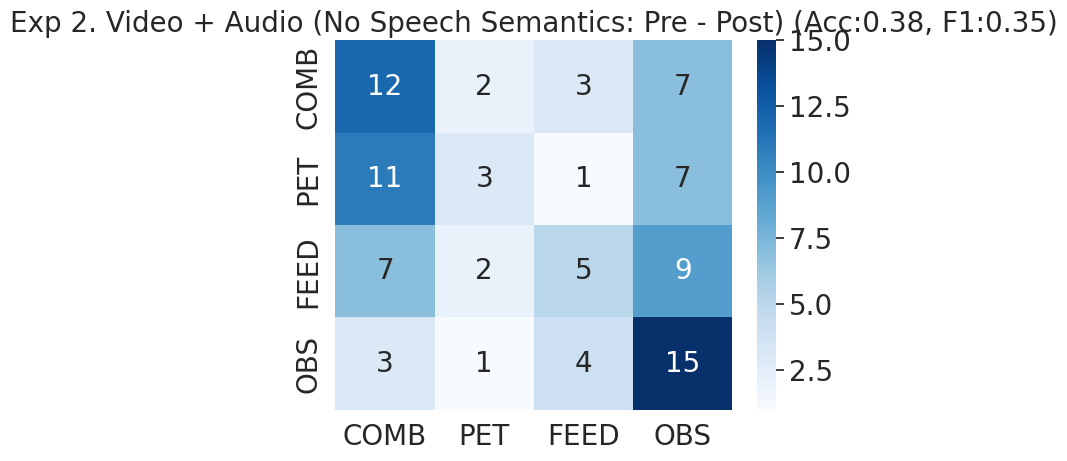

In [29]:
df_eval_2 = data_analysis_helper.merge_and_show_accuracy(
    df_list=[df_result_2_diff],
    threshold_type="mean",
    chart_helper=chart_helper,
    title="Exp 2. Video + Audio (No Speech Semantics: Pre - Post)",
    font_size=20,
)

# Experiment 3 - Video + Audio + Speech Context (`Full Audiovisual + Speech Semantics`)
Evaluates Pre-test and Post-test audio-merged videos independently (`video_only=False`) integrating **visual cues, non-semantic vocal acoustics, and the semantic meaning of spoken words**, then subtracts Post-test predictions from Pre-test predictions ($\text{Improvement} = \text{Pre} - \text{Post}$).

## Step 1: Pre-Test Video Definition, Trial Check & Formal Prediction (`experiment_step="pre"`)

In [30]:
experiment_helper_3_pre = experiment_helper.copy()
experiment_helper_3_pre.define_experiment(
    participant_sn_range=list_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "merged_video_pre.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_experiment_3_pre.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="pre",
    video_only=False,
    use_pre_and_post=False,
    interpreters=[],
    template_main=template_with_speech_text,
    template_cot="",
    template_knowledge_injection="",
    template_tools="",
)
df_video_3_pre = experiment_helper_3_pre.get_df_video_path()
display(df_video_3_pre.head())

[INFO] Pickle file exists; reading it directly: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/merged_video_pre.plk


,Experiment Name,Participant SN,Experiment Step,Pre Video Path,Post Video Path,Video Path,Pre Audio Path,Post Audio Path,Pre Merged File Path,Post Merged File Path,...,STAI_AP_pre,STAI_AP_post,STAI_AP_improvement,in_prediction_scope,uploaded_file_pre_video_only,uploaded_file_video_only,uploaded_file_pre_video_merged,uploaded_file_video_merged,Pre Compressed Video Path,Compressed Video Path
0,PS-035,004,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,15,15,0,True,None,None,None,name='files/p6kkueikaqdo' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
1,PS-035,005,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,13,11,2,True,None,None,None,name='files/c1hs5udfoukx' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
2,PS-035,008,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,19,13,6,True,None,None,None,name='files/wu49xfyyff8z' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
3,PS-035,011,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,16,14,2,True,None,None,None,name='files/3anvhsd80jec' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
4,PS-035,012,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,13,10,3,True,None,None,None,name='files/ajyr289ooyot' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...


In [31]:
# [Trial Check Before Formal Step 1] Test on 1 participant first to verify audio-merged compression, upload, and score parsing
if run_trial:
    df_trial_3_pre = experiment_helper_3_pre.run_trial_before_formal(n_trial=1, over_ride_existing=False, verbose=True)
    display(df_trial_3_pre[["Participant SN", "Group Name", "STAI_AA_pre", "stai_aa", "STAI_AP_pre", "stai_ap", "STAI_pre", "stai_total", "explanation"]])

In [32]:
# [Formal Execution — Experiment 3 Step 1 (All 92 Participants, Pre-Test)]
if run_experiments:
    df_result_3_pre = experiment_helper_3_pre.run_exp_pet_therapy(over_ride_existing=False, max_workers=4)
else:
    df_result_3_pre = experiment_helper_3_pre.get_df_experiment_results()

=== run_exp_pet_therapy (PRE) start ===
[Participant 011 - PRE] Video already uploaded and active.
[Participant 004 - PRE] Video already uploaded and active.
[Participant 008 - PRE] Video already uploaded and active.
[Participant 005 - PRE] Video already uploaded and active.
[Participant 019 - PRE] Video already uploaded and active.
[Participant 012 - PRE] Video already uploaded and active.
[Participant 022 - PRE] Video already uploaded and active.
[Participant 017 - PRE] Video already uploaded and active.
[Participant 027 - PRE] Video already uploaded and active.
[Participant 026 - PRE] Video already uploaded and active.
[Participant 024 - PRE] Video already uploaded and active.
[Participant 025 - PRE] Video already uploaded and active.
[Participant 029 - PRE] Video already uploaded and active.
[Participant 032 - PRE] Video already uploaded and active.
[Participant 031 - PRE] Video already uploaded and active.
[Participant 028 - PRE] Video already uploaded and active.
[Participant 033

## Step 2: Post-Test Video Definition, Trial Check & Formal Prediction (`experiment_step="post"`)

In [33]:
experiment_helper_3_post = experiment_helper.copy()
experiment_helper_3_post.define_experiment(
    participant_sn_range=list_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "merged_video_post.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_experiment_3_post.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="post",
    video_only=False,
    use_pre_and_post=False,
    interpreters=[],
    template_main=template_with_speech_text,
    template_cot="",
    template_knowledge_injection="",
    template_tools="",
)
df_video_3_post = experiment_helper_3_post.get_df_video_path()
display(df_video_3_post.head())

[INFO] Pickle file exists; reading it directly: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/merged_video_post.plk


,Experiment Name,Participant SN,Experiment Step,Pre Video Path,Post Video Path,Video Path,Pre Audio Path,Post Audio Path,Pre Merged File Path,Post Merged File Path,...,STAI_AP_pre,STAI_AP_post,STAI_AP_improvement,in_prediction_scope,uploaded_file_pre_video_only,uploaded_file_video_only,uploaded_file_pre_video_merged,uploaded_file_video_merged,Pre Compressed Video Path,Compressed Video Path
0,PS-035,004,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,15,15,0,True,None,None,None,name='files/t774mv3z9tdv' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
1,PS-035,005,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,13,11,2,True,None,None,None,name='files/mfhyinaioqk2' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
2,PS-035,008,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,19,13,6,True,None,None,None,name='files/r30cdbz9ab24' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
3,PS-035,011,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,16,14,2,True,None,None,None,name='files/74oyp7v92nqo' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
4,PS-035,012,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,13,10,3,True,None,None,None,name='files/d5m31skm4btz' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...


In [34]:
# [Trial Check Before Formal Step 2] Test on 1 participant first to verify audio-merged compression, upload, and score parsing
if run_trial:
    df_trial_3_post = experiment_helper_3_post.run_trial_before_formal(n_trial=1, over_ride_existing=False, verbose=True)
    display(df_trial_3_post[["Participant SN", "Group Name", "STAI_AA_post", "stai_aa", "STAI_AP_post", "stai_ap", "STAI_post", "stai_total", "explanation"]])

In [35]:
# [Formal Execution — Experiment 3 Step 2 (All 92 Participants, Post-Test)]
if run_experiments:
    df_result_3_post = experiment_helper_3_post.run_exp_pet_therapy(over_ride_existing=False, max_workers=4)
else:
    df_result_3_post = experiment_helper_3_post.get_df_experiment_results()

=== run_exp_pet_therapy (POST) start ===
[Participant 004 - POST] Video already uploaded and active.
[Participant 011 - POST] Video already uploaded and active.
[Participant 005 - POST] Video already uploaded and active.
[Participant 008 - POST] Video already uploaded and active.
[Participant 012 - POST] Video already uploaded and active.
[Participant 019 - POST] Video already uploaded and active.
[Participant 017 - POST] Video already uploaded and active.
[Participant 022 - POST] Video already uploaded and active.
[Participant 026 - POST] Video already uploaded and active.
[Participant 025 - POST] Video already uploaded and active.
[Participant 024 - POST] Video already uploaded and active.
[Participant 027 - POST] Video already uploaded and active.
[Participant 029 - POST] Video already uploaded and active.
[Participant 031 - POST] Video already uploaded and active.
[Participant 028 - POST] Video already uploaded and active.
[Participant 032 - POST] Video already uploaded and active.

## Step 3: Subtract Pre-Test and Post-Test Predictions (`Improvement = Pre - Post`)

In [36]:
df_result_3_diff = experiment_helper_3_post.compute_pre_post_difference(
    df_pre=df_result_3_pre,
    df_post=df_result_3_post,
    path_pickle_diff=os.path.join(path_paper, "temp", "pickle", "df_experiment_3_diff.plk"),
)
df_result_3_diff.to_csv("df_results_exp_3_diff.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(df_result_3_diff[[
        "Group Name", "Participant SN",
        "STAI_AA_pre", "stai_aa_pre_pred", "STAI_AA_post", "stai_aa_post_pred", "STAI_AA_improvement", "stai_aa_imp_pred",
        "STAI_AP_pre", "stai_ap_pre_pred", "STAI_AP_post", "stai_ap_post_pred", "STAI_AP_improvement", "stai_ap_imp_pred",
        "STAI_improvement", "stai_total_imp_pred",
    ]].head(10))

[INFO] Subtracted Pre-Post difference DataFrame saved to: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/df_experiment_3_diff.plk


,Group Name,Participant SN,STAI_AA_pre,stai_aa_pre_pred,STAI_AA_post,stai_aa_post_pred,STAI_AA_improvement,stai_aa_imp_pred,STAI_AP_pre,stai_ap_pre_pred,STAI_AP_post,stai_ap_post_pred,STAI_AP_improvement,stai_ap_imp_pred,STAI_improvement,stai_total_imp_pred
0,COMB,004,20,24.0,13,15.0,7,9.0,15,21.0,15,12.0,0,9.0,7,18.0
1,PET,005,27,24.0,23,16.0,4,8.0,13,21.0,11,12.0,2,9.0,6,17.0
2,FEED,008,15,16.0,21,16.0,-6,0.0,19,12.0,13,12.0,6,0.0,0,0.0
3,COMB,011,29,24.0,21,18.0,8,6.0,16,21.0,14,12.0,2,9.0,10,15.0
4,PET,012,14,24.0,12,16.0,2,8.0,13,21.0,10,15.0,3,6.0,5,14.0
5,COMB,017,13,21.0,10,14.0,3,7.0,11,16.0,10,12.0,1,4.0,4,11.0
6,FEED,019,23,18.0,20,18.0,3,0.0,11,16.0,10,14.0,1,2.0,4,2.0
7,PET,022,11,16.0,12,15.0,-1,1.0,15,13.0,21,12.0,-6,1.0,-7,2.0
8,COMB,024,21,21.0,21,18.0,0,3.0,12,23.0,11,14.0,1,9.0,1,12.0
9,FEED,025,35,16.0,21,16.0,14,0.0,25,15.0,19,13.0,6,2.0,20,2.0


## Step 4: Print Out Results (Experiment 3 — Video + Audio + Speech Context)

=== Exp 3. Video + Audio + Speech Context (Pre - Post) Evaluation ===
STAI-AA component threshold (mean): 3.011
STAI-AP component threshold (mean): 3.565

[STAI Two-Component & Total Psychometric Regression (Exp 3. Video + Audio + Speech Context (Pre - Post))]:
  Pre-Test  | STAI-AA (Calmness/Security Absence, 10-40) (n=92): MAE=5.728, RMSE=6.952, R²=-0.358, Pearson r=0.043 (p=0.6824), Spearman ρ=0.078 (p=0.4579)
  Pre-Test  | STAI-AP (Acute Tension Presence, 10-40)    (n=92): MAE=5.304, RMSE=6.630, R²=-0.723, Pearson r=0.026 (p=0.8060), Spearman ρ=0.116 (p=0.2689)
  Pre-Test  | STAI-Total (State Anxiety Total, 20-80)    (n=92): MAE=9.402, RMSE=11.786, R²=-0.568, Pearson r=0.038 (p=0.7166), Spearman ρ=0.090 (p=0.3936)
  Post-Test | STAI-AA (Calmness/Security Absence, 10-40) (n=92): MAE=5.065, RMSE=6.217, R²=-0.318, Pearson r=0.131 (p=0.2117), Spearman ρ=0.192 (p=0.0670)
  Post-Test | STAI-AP (Acute Tension Presence, 10-40)    (n=92): MAE=3.457, RMSE=4.504, R²=-0.114, Pearson r=0.257 (p

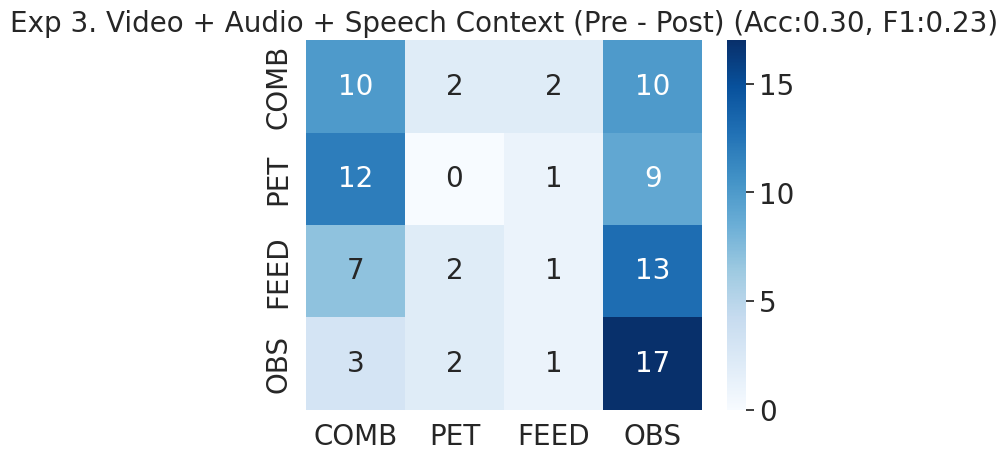

In [37]:
df_eval_3 = data_analysis_helper.merge_and_show_accuracy(
    df_list=[df_result_3_diff],
    threshold_type="mean",
    chart_helper=chart_helper,
    title="Exp 3. Video + Audio + Speech Context (Pre - Post)",
    font_size=20,
)

# Summary Comparison Across All Three Modality Experiments (`Video Only` vs. `Video + Audio` vs. `Video + Audio + Speech Context`)

In [38]:
df_modality_comparison = data_analysis_helper.compare_modality_experiments({
    "Exp 1: Video Only": df_result_1_diff,
    "Exp 2: Video + Audio (No Speech Text)": df_result_2_diff,
    "Exp 3: Video + Audio + Speech Context": df_result_3_diff,
})
display(df_modality_comparison)

=== Cross-Modality Comparison Summary (Pre, Post, and Pre - Post Improvement) ===
                           Experiment                    Stage          Construct  n   MAE   RMSE     R2  Pearson_r    p_r  Spearman_rho  p_rho
                    Exp 1: Video Only                 Pre-Test    STAI-AA (10-40) 92 5.511  6.956 -0.359      0.141 0.1788         0.134 0.2045
                    Exp 1: Video Only                 Pre-Test    STAI-AP (10-40) 92 4.163  5.644 -0.249      0.022 0.8363        -0.039 0.7089
                    Exp 1: Video Only                 Pre-Test STAI-Total (20-80) 92 8.217 10.735 -0.301      0.125 0.2358         0.128 0.2225
                    Exp 1: Video Only                Post-Test    STAI-AA (10-40) 92 5.250  6.387 -0.391     -0.050 0.6340        -0.029 0.7860
                    Exp 1: Video Only                Post-Test    STAI-AP (10-40) 92 3.576  4.992 -0.369      0.063 0.5522         0.020 0.8478
                    Exp 1: Video Only                P

,Experiment,Stage,Construct,n,MAE,RMSE,R2,Pearson_r,p_r,Spearman_rho,p_rho
0,Exp 1: Video Only,Pre-Test,STAI-AA (10-40),92,5.511,6.956,-0.359,0.141,0.1788,0.134,0.2045
1,Exp 1: Video Only,Pre-Test,STAI-AP (10-40),92,4.163,5.644,-0.249,0.022,0.8363,-0.039,0.7089
2,Exp 1: Video Only,Pre-Test,STAI-Total (20-80),92,8.217,10.735,-0.301,0.125,0.2358,0.128,0.2225
3,Exp 1: Video Only,Post-Test,STAI-AA (10-40),92,5.250,6.387,-0.391,-0.050,0.6340,-0.029,0.7860
4,Exp 1: Video Only,Post-Test,STAI-AP (10-40),92,3.576,4.992,-0.369,0.063,0.5522,0.020,0.8478
5,Exp 1: Video Only,Post-Test,STAI-Total (20-80),92,7.109,9.331,-0.471,-0.001,0.9936,-0.012,0.9082
6,Exp 1: Video Only,Improvement (Pre - Post),Delta STAI-AA,92,4.174,5.302,-0.644,0.020,0.8517,0.055,0.6058
7,Exp 1: Video Only,Improvement (Pre - Post),Delta STAI-AP,92,3.500,4.919,-0.774,0.098,0.3539,0.120,0.2532
8,Exp 1: Video Only,Improvement (Pre - Post),Delta STAI-Total,92,6.739,8.938,-1.053,0.075,0.4759,0.133,0.2060
9,Exp 2: Video + Audio (No Speech Text),Pre-Test,STAI-AA (10-40),92,5.533,6.946,-0.356,0.059,0.5760,0.082,0.4365


# Experiment 4 - Video + Audio + Speech Context + Physio (`Heart Rate & Facial Thermal Imaging`)

## Definition
In **Experiment 4**, following the architecture of Experiment 4 in `experiments_1_9.ipynb`, we augment the full audiovisual + speech context input (**Experiment 3**) with objective physiological indicators captured concurrently during the Pre-test and Post-test recordings:
1. **Cardiovascular & Heart Rate Variability (`HeartRateInterpreter`)**: Mean heart rate (`mean_hr`), root mean square of successive RR interval differences (`rmssd`, vagal/parasympathetic regulation), standard deviation of NN intervals (`sdnn`, overall autonomic flexibility), systolic blood pressure (`sbp`), and diastolic blood pressure (`dbp`).
2. **Infrared Facial Thermal Imaging (`ThermalInterpreter`)**: Nasal tip temperature (`nose_tip_temperature`, indexing alpha-adrenergic sympathetic vasoconstriction/cooling under acute stress vs. vasodilation/warming under relaxation), left cheek temperature (`left_cheek_temperature`), and right cheek temperature (`right_cheek_temperature`).

Consistent with Experiments 1–3:
- **Step 1 (`experiment_step="pre"`)**: Evaluates the Pre-test video paired with **Pre-test physiological indicators** (`pre_*`) and reuses the cached Gemini video URIs in `merged_video_pre.plk` (zero redundant video uploads).
- **Step 2 (`experiment_step="post"`)**: Evaluates the Post-test video paired with **Post-test physiological indicators** (`post_*`) and reuses the cached Gemini video URIs in `merged_video_post.plk` (zero redundant video uploads).
- **Step 3 (`Pre - Post` Subtraction)**: Computes $\Delta\text{STAI\_AA} = \text{STAI\_AA}_{\text{pre}} - \text{STAI\_AA}_{\text{post}}$, $\Delta\text{STAI\_AP} = \text{STAI\_AP}_{\text{pre}} - \text{STAI\_AP}_{\text{post}}$, and $\Delta\text{STAI\_Total} = \text{STAI\_Total}_{\text{pre}} - \text{STAI\_Total}_{\text{post}}$.

### Heart Rate & Heart Rate Variability (HRV) Criteria (`Pre` and `Post`)

In [39]:
# ------------------------------------------------------------------
# Heart Rate, HRV (rMSSD, SDNN), and Blood Pressure Criteria Lists
# Quantile thresholds ('q3' = 75th percentile, 'q1' = 25th percentile)
# are computed on the Study 2 feature distribution (df_features).
# ------------------------------------------------------------------

heart_rate_criteria_list_pre = [
    # Heart Rate Level (mean_hr)
    ["pre_mean_hr", ">", "q3",
     "The heart rate is relatively high, suggesting increased sympathetic activation and physiological arousal, which often accompanies acute somatic tension (higher stai_ap) or reduced calmness (higher stai_aa)."],
    ["pre_mean_hr", "<=", "q1",
     "The heart rate is relatively low, suggesting a calmer physiological state, autonomic settling, and greater psychological ease (lower stai_aa and lower stai_ap)."],

    # rMSSD (parasympathetic / vagal regulation)
    ["pre_rmssd", ">", "q3",
     "High rMSSD indicates strong parasympathetic (vagal) activity and flexible beat-to-beat heart rate regulation, which is associated with calmness, comfort, and psychological security (lower stai_aa and lower stai_ap)."],
    ["pre_rmssd", "<=", "q1",
     "Low rMSSD indicates reduced parasympathetic regulation and lower beat-to-beat heart rate variability, which may occur during acute tension, stress, or difficulty relaxing (higher stai_ap and higher stai_aa)."],

    # SDNN (global autonomic flexibility)
    ["pre_sdnn", ">", "q3",
     "A higher SDNN indicates greater overall heart rate variability, suggesting flexible autonomic regulation that accompanies calm and regulated emotional states (lower stai_aa)."],
    ["pre_sdnn", "<=", "q1",
     "A lower SDNN indicates reduced overall heart rate variability, which may occur during physiologically stressed, tense, or guarded states (higher stai_ap and higher stai_aa)."],

    # Blood Pressure (SBP & DBP)
    ["pre_sbp", ">", "q3",
     "Systolic blood pressure is relatively elevated, reflecting heightened cardiovascular sympathetic tone that may accompany acute tension or stress (higher stai_ap)."],
    ["pre_sbp", "<=", "q1",
     "Systolic blood pressure is relatively low, reflecting relaxed cardiovascular tone consistent with physiological calmness (lower stai_aa and lower stai_ap)."],
    ["pre_dbp", ">", "q3",
     "Diastolic blood pressure is relatively elevated, suggesting increased peripheral vascular resistance that may occur during tense or stressed states (higher stai_ap)."],
    ["pre_dbp", "<=", "q1",
     "Diastolic blood pressure is relatively low, suggesting relaxed peripheral vascular tone and autonomic ease (lower stai_aa)."],
]

heart_rate_criteria_list_post = [
    # Heart Rate Level (mean_hr)
    ["post_mean_hr", ">", "q3",
     "The heart rate is relatively high, suggesting increased sympathetic activation and physiological arousal, which often accompanies acute somatic tension (higher stai_ap) or reduced calmness (higher stai_aa)."],
    ["post_mean_hr", "<=", "q1",
     "The heart rate is relatively low, suggesting a calmer physiological state, autonomic settling, and greater psychological ease (lower stai_aa and lower stai_ap)."],

    # rMSSD (parasympathetic / vagal regulation)
    ["post_rmssd", ">", "q3",
     "High rMSSD indicates strong parasympathetic (vagal) activity and flexible beat-to-beat heart rate regulation, which is associated with calmness, comfort, and psychological security (lower stai_aa and lower stai_ap)."],
    ["post_rmssd", "<=", "q1",
     "Low rMSSD indicates reduced parasympathetic regulation and lower beat-to-beat heart rate variability, which may occur during acute tension, stress, or difficulty relaxing (higher stai_ap and higher stai_aa)."],

    # SDNN (global autonomic flexibility)
    ["post_sdnn", ">", "q3",
     "A higher SDNN indicates greater overall heart rate variability, suggesting flexible autonomic regulation that accompanies calm and regulated emotional states (lower stai_aa)."],
    ["post_sdnn", "<=", "q1",
     "A lower SDNN indicates reduced overall heart rate variability, which may occur during physiologically stressed, tense, or guarded states (higher stai_ap and higher stai_aa)."],

    # Blood Pressure (SBP & DBP)
    ["post_sbp", ">", "q3",
     "Systolic blood pressure is relatively elevated, reflecting heightened cardiovascular sympathetic tone that may accompany acute tension or stress (higher stai_ap)."],
    ["post_sbp", "<=", "q1",
     "Systolic blood pressure is relatively low, reflecting relaxed cardiovascular tone consistent with physiological calmness (lower stai_aa and lower stai_ap)."],
    ["post_dbp", ">", "q3",
     "Diastolic blood pressure is relatively elevated, suggesting increased peripheral vascular resistance that may occur during tense or stressed states (higher stai_ap)."],
    ["post_dbp", "<=", "q1",
     "Diastolic blood pressure is relatively low, suggesting relaxed peripheral vascular tone and autonomic ease (lower stai_aa)."],
]

### Facial Thermal Imaging Criteria (`Pre` and `Post`)

In [40]:
# ------------------------------------------------------------------
# Infrared Facial Thermal Imaging Criteria Lists
# Covers Nasal Tip, Left Cheek, and Right Cheek Regions.
# Nasal cooling reflects alpha-adrenergic sympathetic vasoconstriction
# under acute tension, whereas nasal/cheek warming reflects peripheral
# cutaneous vasodilation during affiliative comfort and relaxation.
# ------------------------------------------------------------------

thermal_criteria_list_pre = [
    # Nasal Tip Region (pre_nose_tip_temperature)
    ["pre_nose_tip_temperature", "<=", "q1",
     "This region lies at the nasal tip. Cooling in the nose area (relatively low nasal tip temperature) often occurs due to alpha-adrenergic sympathetic vasoconstriction during acute stress, nervousness, or emotional tension (higher stai_ap and higher stai_aa)."],
    ["pre_nose_tip_temperature", ">", "q3",
     "This region lies at the nasal tip. Higher nasal tip temperature reflects reduced sympathetic vasoconstriction and peripheral cutaneous vasodilation, which occurs during parasympathetic relaxation, warmth, and psychological security (lower stai_aa and lower stai_ap)."],

    # Left Cheek Region (pre_left_cheek_temperature)
    ["pre_left_cheek_temperature", ">", "q3",
     "This region lies in the left cheek area. Increased cheek temperature reflects greater facial cutaneous blood flow and warmth during affiliative comfort, relaxation, and positive ease (lower stai_aa)."],
    ["pre_left_cheek_temperature", "<=", "q1",
     "This region lies in the left cheek area. Relatively low cheek temperature suggests peripheral vasoconstriction or reduced facial warmth, which may accompany tension or an absence of comfort (higher stai_aa and higher stai_ap)."],

    # Right Cheek Region (pre_right_cheek_temperature)
    ["pre_right_cheek_temperature", ">", "q3",
     "This region lies in the right cheek area. Increased cheek temperature reflects greater facial cutaneous blood flow and warmth during affiliative comfort, relaxation, and positive ease (lower stai_aa)."],
    ["pre_right_cheek_temperature", "<=", "q1",
     "This region lies in the right cheek area. Relatively low cheek temperature suggests peripheral vasoconstriction or reduced facial warmth, which may accompany tension or an absence of comfort (higher stai_aa and higher stai_ap)."],
]

thermal_criteria_list_post = [
    # Nasal Tip Region (post_nose_tip_temperature)
    ["post_nose_tip_temperature", "<=", "q1",
     "This region lies at the nasal tip. Cooling in the nose area (relatively low nasal tip temperature) often occurs due to alpha-adrenergic sympathetic vasoconstriction during acute stress, nervousness, or emotional tension (higher stai_ap and higher stai_aa)."],
    ["post_nose_tip_temperature", ">", "q3",
     "This region lies at the nasal tip. Higher nasal tip temperature reflects reduced sympathetic vasoconstriction and peripheral cutaneous vasodilation, which occurs during parasympathetic relaxation, warmth, and psychological security (lower stai_aa and lower stai_ap)."],

    # Left Cheek Region (post_left_cheek_temperature)
    ["post_left_cheek_temperature", ">", "q3",
     "This region lies in the left cheek area. Increased cheek temperature reflects greater facial cutaneous blood flow and warmth during affiliative comfort, relaxation, and positive ease (lower stai_aa)."],
    ["post_left_cheek_temperature", "<=", "q1",
     "This region lies in the left cheek area. Relatively low cheek temperature suggests peripheral vasoconstriction or reduced facial warmth, which may accompany tension or an absence of comfort (higher stai_aa and higher stai_ap)."],

    # Right Cheek Region (post_right_cheek_temperature)
    ["post_right_cheek_temperature", ">", "q3",
     "This region lies in the right cheek area. Increased cheek temperature reflects greater facial cutaneous blood flow and warmth during affiliative comfort, relaxation, and positive ease (lower stai_aa)."],
    ["post_right_cheek_temperature", "<=", "q1",
     "This region lies in the right cheek area. Relatively low cheek temperature suggests peripheral vasoconstriction or reduced facial warmth, which may accompany tension or an absence of comfort (higher stai_aa and higher stai_ap)."],
]

## Tools (`ThermalInterpreter` & `HeartRateInterpreter`)

In [41]:
from psychai.feature.feature_interpreter.feature_interpreter import InterpreterBuilder
interpreter_builder = InterpreterBuilder()

# Build Pre-test Physiological Interpreters
ThermalInterpreterPre = interpreter_builder.build_interpreter_class(
    thermal_criteria_list_pre, class_name="ThermalInterpreterPre", df=df_features
)
thermal_interpreter_pre = ThermalInterpreterPre()

HeartRateInterpreterPre = interpreter_builder.build_interpreter_class(
    heart_rate_criteria_list_pre, class_name="HeartRateInterpreterPre", df=df_features
)
heart_rate_interpreter_pre = HeartRateInterpreterPre()

interpreters_4_pre = [
    thermal_interpreter_pre,
    heart_rate_interpreter_pre,
]

# Build Post-test Physiological Interpreters
ThermalInterpreterPost = interpreter_builder.build_interpreter_class(
    thermal_criteria_list_post, class_name="ThermalInterpreterPost", df=df_features
)
thermal_interpreter_post = ThermalInterpreterPost()

HeartRateInterpreterPost = interpreter_builder.build_interpreter_class(
    heart_rate_criteria_list_post, class_name="HeartRateInterpreterPost", df=df_features
)
heart_rate_interpreter_post = HeartRateInterpreterPost()

interpreters_4_post = [
    thermal_interpreter_post,
    heart_rate_interpreter_post,
]

tools_template_physio = """
The following physiological features were obtained using external analytical tools (infrared facial thermal imaging and cardiovascular/heart rate variability sensors) recorded concurrently with this video. Use these physiological results as supporting evidence in your assessment when determining the scores for `stai_aa` (Absence of Calmness & Security) and `stai_ap` (Presence of Acute Tension).

Thermal imaging analysis result: {0}

Heart rate variability analysis result: {1}
"""

# Preview physiological interpreter output on the first participant
_sample_feats = experiment_helper.get_user_features_from_df(df_features, list_users[0])
print(f"Sample Participant {list_users[0]:03d} [PRE] Thermal:", thermal_interpreter_pre.upload_and_get_text_output(_sample_feats))
print(f"Sample Participant {list_users[0]:03d} [PRE] Heart Rate:", heart_rate_interpreter_pre.upload_and_get_text_output(_sample_feats))
print(f"Sample Participant {list_users[0]:03d} [POST] Thermal:", thermal_interpreter_post.upload_and_get_text_output(_sample_feats))
print(f"Sample Participant {list_users[0]:03d} [POST] Heart Rate:", heart_rate_interpreter_post.upload_and_get_text_output(_sample_feats))

Sample Participant 004 [PRE] Thermal: This region lies in the left cheek area. Relatively low cheek temperature suggests peripheral vasoconstriction or reduced facial warmth, which may accompany tension or an absence of comfort (higher stai_aa and higher stai_ap).
Sample Participant 004 [PRE] Heart Rate: Systolic blood pressure is relatively elevated, reflecting heightened cardiovascular sympathetic tone that may accompany acute tension or stress (higher stai_ap).
Sample Participant 004 [POST] Thermal: This region lies in the right cheek area. Increased cheek temperature reflects greater facial cutaneous blood flow and warmth during affiliative comfort, relaxation, and positive ease (lower stai_aa).
Sample Participant 004 [POST] Heart Rate: Systolic blood pressure is relatively elevated, reflecting heightened cardiovascular sympathetic tone that may accompany acute tension or stress (higher stai_ap).；Diastolic blood pressure is relatively elevated, suggesting increased peripheral vascu

## Step 1: Pre-Test Video + Physio Definition, Trial Check & Formal Prediction (`experiment_step="pre"`)

In [42]:
experiment_helper_4_pre = experiment_helper.copy()
experiment_helper_4_pre.define_experiment(
    participant_sn_range=list_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "merged_video_pre.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_experiment_4_pre.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="pre",
    video_only=False,
    use_pre_and_post=False,
    interpreters=interpreters_4_pre,
    template_main=template_with_speech_text,
    template_cot="",
    template_knowledge_injection="",
    template_tools=tools_template_physio,
    attach_video=True,
)
df_video_4_pre = experiment_helper_4_pre.get_df_video_path()
display(df_video_4_pre.head())

[INFO] Pickle file exists; reading it directly: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/merged_video_pre.plk


,Experiment Name,Participant SN,Experiment Step,Pre Video Path,Post Video Path,Video Path,Pre Audio Path,Post Audio Path,Pre Merged File Path,Post Merged File Path,...,STAI_AP_pre,STAI_AP_post,STAI_AP_improvement,in_prediction_scope,uploaded_file_pre_video_only,uploaded_file_video_only,uploaded_file_pre_video_merged,uploaded_file_video_merged,Pre Compressed Video Path,Compressed Video Path
0,PS-035,004,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,15,15,0,True,None,None,None,name='files/p6kkueikaqdo' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
1,PS-035,005,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,13,11,2,True,None,None,None,name='files/c1hs5udfoukx' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
2,PS-035,008,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,19,13,6,True,None,None,None,name='files/wu49xfyyff8z' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
3,PS-035,011,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,16,14,2,True,None,None,None,name='files/3anvhsd80jec' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
4,PS-035,012,pre,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,13,10,3,True,None,None,None,name='files/ajyr289ooyot' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...


In [43]:
# [Trial Check Before Formal Step 1] Test on 1 participant first to verify cached video URI reuse, physiological prompt injection, and score parsing
if run_trial:
    df_trial_4_pre = experiment_helper_4_pre.run_trial_before_formal(n_trial=1, over_ride_existing=False, verbose=True)
    display(df_trial_4_pre[["Participant SN", "Group Name", "STAI_AA_pre", "stai_aa", "STAI_AP_pre", "stai_ap", "STAI_pre", "stai_total", "explanation"]])

In [44]:
# [Formal Execution — Experiment 4 Step 1 (All 92 Participants, Pre-Test Video + Audio + Speech + Physio)]
run_experiments = True
if run_experiments:
    df_result_4_pre = experiment_helper_4_pre.run_exp_pet_therapy(over_ride_existing=False, max_workers=4)
else:
    df_result_4_pre = experiment_helper_4_pre.get_df_experiment_results()

=== run_exp_pet_therapy (PRE) start ===
[Participant 005 - PRE] Video already uploaded and active.
[Participant 004 - PRE] Video already uploaded and active.
[Participant 008 - PRE] Video already uploaded and active.
[Participant 011 - PRE] Video already uploaded and active.
[Participant 019 - PRE] Video already uploaded and active.
[Participant 017 - PRE] Video already uploaded and active.
[Participant 022 - PRE] Video already uploaded and active.
[Participant 012 - PRE] Video already uploaded and active.
[Participant 025 - PRE] Video already uploaded and active.
[Participant 026 - PRE] Video already uploaded and active.
[Participant 024 - PRE] Video already uploaded and active.
[Participant 027 - PRE] Video already uploaded and active.
[Participant 028 - PRE] Video already uploaded and active.
[Participant 029 - PRE] Video already uploaded and active.
[Participant 031 - PRE] Video already uploaded and active.
[Participant 032 - PRE] Video already uploaded and active.
[Participant 036

## Step 2: Post-Test Video + Physio Definition, Trial Check & Formal Prediction (`experiment_step="post"`)

In [45]:
experiment_helper_4_post = experiment_helper.copy()
experiment_helper_4_post.define_experiment(
    participant_sn_range=list_users,
    path_pickle_df_video=os.path.join(path_paper, "temp", "pickle", "merged_video_post.plk"),
    path_pickle_df_experiment_results=os.path.join(path_paper, "temp", "pickle", "df_experiment_4_post.plk"),
    path_compressed_video=os.path.join(path_paper, "temp", "compressed_video"),
    experiment_step="post",
    video_only=False,
    use_pre_and_post=False,
    interpreters=interpreters_4_post,
    template_main=template_with_speech_text,
    template_cot="",
    template_knowledge_injection="",
    template_tools=tools_template_physio,
    attach_video=True,
)
df_video_4_post = experiment_helper_4_post.get_df_video_path()
display(df_video_4_post.head())

[INFO] Pickle file exists; reading it directly: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/merged_video_post.plk


,Experiment Name,Participant SN,Experiment Step,Pre Video Path,Post Video Path,Video Path,Pre Audio Path,Post Audio Path,Pre Merged File Path,Post Merged File Path,...,STAI_AP_pre,STAI_AP_post,STAI_AP_improvement,in_prediction_scope,uploaded_file_pre_video_only,uploaded_file_video_only,uploaded_file_pre_video_merged,uploaded_file_video_merged,Pre Compressed Video Path,Compressed Video Path
0,PS-035,004,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,15,15,0,True,None,None,None,name='files/t774mv3z9tdv' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
1,PS-035,005,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,13,11,2,True,None,None,None,name='files/mfhyinaioqk2' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
2,PS-035,008,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,19,13,6,True,None,None,None,name='files/r30cdbz9ab24' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
3,PS-035,011,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,16,14,2,True,None,None,None,name='files/74oyp7v92nqo' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...
4,PS-035,012,post,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,/mnt/c/Working/google/Programming/Python/wsl3/...,...,13,10,3,True,None,None,None,name='files/d5m31skm4btz' display_name=None mi...,None,/mnt/c/Working/google/Programming/Python/wsl3/...


In [46]:
# [Trial Check Before Formal Step 2] Test on 1 participant first to verify cached video URI reuse, physiological prompt injection, and score parsing
if run_trial:
    df_trial_4_post = experiment_helper_4_post.run_trial_before_formal(n_trial=1, over_ride_existing=False, verbose=True)
    display(df_trial_4_post[["Participant SN", "Group Name", "STAI_AA_post", "stai_aa", "STAI_AP_post", "stai_ap", "STAI_post", "stai_total", "explanation"]])

In [47]:
# [Formal Execution — Experiment 4 Step 2 (All 92 Participants, Post-Test Video + Audio + Speech + Physio)]
run_experiments = True
if run_experiments:
    df_result_4_post = experiment_helper_4_post.run_exp_pet_therapy(over_ride_existing=False, max_workers=4)
else:
    df_result_4_post = experiment_helper_4_post.get_df_experiment_results()
run_experiments = False

=== run_exp_pet_therapy (POST) start ===
[Participant 004 - POST] Video already uploaded and active.
[Participant 005 - POST] Video already uploaded and active.
[Participant 008 - POST] Video already uploaded and active.
[Participant 011 - POST] Video already uploaded and active.
[Participant 017 - POST] Video already uploaded and active.
[Participant 012 - POST] Video already uploaded and active.
[Participant 022 - POST] Video already uploaded and active.
[Participant 019 - POST] Video already uploaded and active.
[Participant 026 - POST] Video already uploaded and active.
[Participant 024 - POST] Video already uploaded and active.
[Participant 027 - POST] Video already uploaded and active.
[Participant 025 - POST] Video already uploaded and active.
[Participant 032 - POST] Video already uploaded and active.
[Participant 029 - POST] Video already uploaded and active.
[Participant 028 - POST] Video already uploaded and active.
[Participant 031 - POST] Video already uploaded and active.

## Step 3: Subtract Pre-Test and Post-Test Predictions (`Improvement = Pre - Post`)

In [48]:
df_result_4_diff = experiment_helper_4_post.compute_pre_post_difference(
    df_pre=df_result_4_pre,
    df_post=df_result_4_post,
    path_pickle_diff=os.path.join(path_paper, "temp", "pickle", "df_experiment_4_diff.plk"),
)
df_result_4_diff.to_csv("df_results_exp_4_diff.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(df_result_4_diff[[
        "Group Name", "Participant SN",
        "STAI_AA_pre", "stai_aa_pre_pred", "STAI_AA_post", "stai_aa_post_pred", "STAI_AA_improvement", "stai_aa_imp_pred",
        "STAI_AP_pre", "stai_ap_pre_pred", "STAI_AP_post", "stai_ap_post_pred", "STAI_AP_improvement", "stai_ap_imp_pred",
        "STAI_improvement", "stai_total_imp_pred",
    ]].head(10))

[INFO] Subtracted Pre-Post difference DataFrame saved to: /mnt/c/Working/google/Programming/Python/wsl3/github_sync/publications/publications/llm_pet_therapy/temp/pickle/df_experiment_4_diff.plk


,Group Name,Participant SN,STAI_AA_pre,stai_aa_pre_pred,STAI_AA_post,stai_aa_post_pred,STAI_AA_improvement,stai_aa_imp_pred,STAI_AP_pre,stai_ap_pre_pred,STAI_AP_post,stai_ap_post_pred,STAI_AP_improvement,stai_ap_imp_pred,STAI_improvement,stai_total_imp_pred
0,COMB,004,20,24.0,13,18.0,7,6.0,15,25.0,15,15.0,0,10.0,7,16.0
1,PET,005,27,18.0,23,14.0,4,4.0,13,16.0,11,12.0,2,4.0,6,8.0
2,FEED,008,15,24.0,21,16.0,-6,8.0,19,21.0,13,12.0,6,9.0,0,17.0
3,COMB,011,29,24.0,21,15.0,8,9.0,16,23.0,14,12.0,2,11.0,10,20.0
4,PET,012,14,24.0,12,16.0,2,8.0,13,25.0,10,15.0,3,10.0,5,18.0
5,COMB,017,13,18.0,10,15.0,3,3.0,11,16.0,10,12.0,1,4.0,4,7.0
6,FEED,019,23,18.0,20,16.0,3,2.0,11,16.0,10,13.0,1,3.0,4,5.0
7,PET,022,11,18.0,12,12.0,-1,6.0,15,16.0,21,11.0,-6,5.0,-7,11.0
8,COMB,024,21,24.0,21,18.0,0,6.0,12,23.0,11,16.0,1,7.0,1,13.0
9,FEED,025,35,16.0,21,16.0,14,0.0,25,15.0,19,15.0,6,0.0,20,0.0


## Step 4: Print Out Results (Experiment 4 — Video + Audio + Speech Context + Physio)

=== Exp 4. Video + Audio + Speech Context + Physio (Pre - Post) Evaluation ===
STAI-AA component threshold (mean): 2.967
STAI-AP component threshold (mean): 3.793

[STAI Two-Component & Total Psychometric Regression (Exp 4. Video + Audio + Speech Context + Physio (Pre - Post))]:
  Pre-Test  | STAI-AA (Calmness/Security Absence, 10-40) (n=92): MAE=6.043, RMSE=7.277, R²=-0.488, Pearson r=-0.032 (p=0.7605), Spearman ρ=-0.085 (p=0.4219)
  Pre-Test  | STAI-AP (Acute Tension Presence, 10-40)    (n=92): MAE=5.565, RMSE=6.782, R²=-0.803, Pearson r=-0.014 (p=0.8945), Spearman ρ=0.129 (p=0.2203)
  Pre-Test  | STAI-Total (State Anxiety Total, 20-80)    (n=92): MAE=9.826, RMSE=12.097, R²=-0.652, Pearson r=-0.027 (p=0.8004), Spearman ρ=-0.061 (p=0.5623)
  Post-Test | STAI-AA (Calmness/Security Absence, 10-40) (n=92): MAE=5.054, RMSE=6.192, R²=-0.307, Pearson r=0.129 (p=0.2193), Spearman ρ=0.140 (p=0.1833)
  Post-Test | STAI-AP (Acute Tension Presence, 10-40)    (n=92): MAE=4.120, RMSE=5.412, R²=-0.

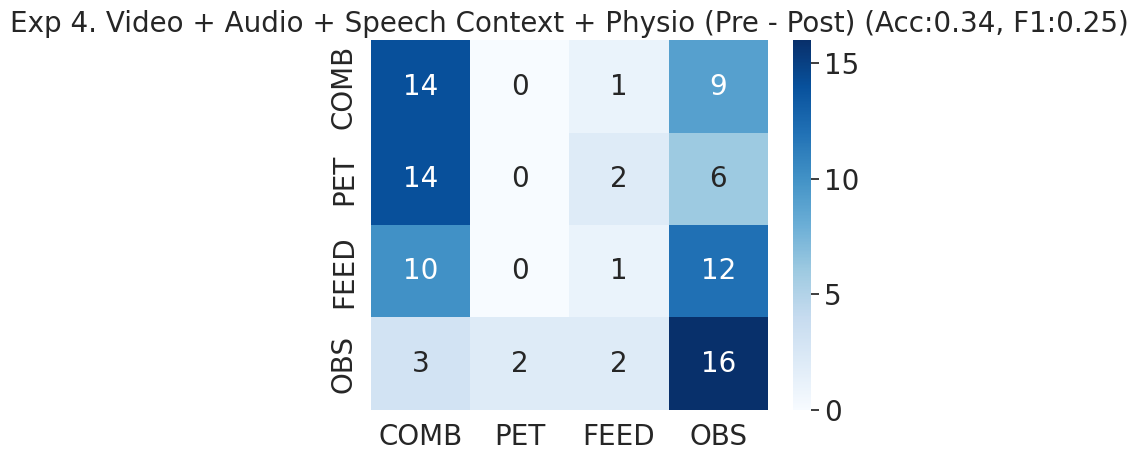

In [49]:
df_eval_4 = data_analysis_helper.merge_and_show_accuracy(
    df_list=[df_result_4_diff],
    threshold_type="mean",
    chart_helper=chart_helper,
    title="Exp 4. Video + Audio + Speech Context + Physio (Pre - Post)",
    font_size=20,
)

# Summary Comparison Across All Four Modality Experiments (`Exp 1` vs. `Exp 2` vs. `Exp 3` vs. `Exp 4`)

In [50]:
df_modality_comparison_all4 = data_analysis_helper.compare_modality_experiments({
    "Exp 1: Video Only": df_result_1_diff,
    "Exp 2: Video + Audio (No Speech Text)": df_result_2_diff,
    "Exp 3: Video + Audio + Speech Context": df_result_3_diff,
    "Exp 4: Video + Audio + Speech + Physio (HR & Thermal)": df_result_4_diff,
})
df_modality_comparison_all4.to_csv("df_modality_comparison_exp1_to_4.csv", index=False)
display(df_modality_comparison_all4)

=== Cross-Modality Comparison Summary (Pre, Post, and Pre - Post Improvement) ===
                                           Experiment                    Stage          Construct  n   MAE   RMSE     R2  Pearson_r    p_r  Spearman_rho  p_rho
                                    Exp 1: Video Only                 Pre-Test    STAI-AA (10-40) 92 5.511  6.956 -0.359      0.141 0.1788         0.134 0.2045
                                    Exp 1: Video Only                 Pre-Test    STAI-AP (10-40) 92 4.163  5.644 -0.249      0.022 0.8363        -0.039 0.7089
                                    Exp 1: Video Only                 Pre-Test STAI-Total (20-80) 92 8.217 10.735 -0.301      0.125 0.2358         0.128 0.2225
                                    Exp 1: Video Only                Post-Test    STAI-AA (10-40) 92 5.250  6.387 -0.391     -0.050 0.6340        -0.029 0.7860
                                    Exp 1: Video Only                Post-Test    STAI-AP (10-40) 92 3.576  4.992 -0.3

,Experiment,Stage,Construct,n,MAE,RMSE,R2,Pearson_r,p_r,Spearman_rho,p_rho
0,Exp 1: Video Only,Pre-Test,STAI-AA (10-40),92,5.511,6.956,-0.359,0.141,0.1788,0.134,0.2045
1,Exp 1: Video Only,Pre-Test,STAI-AP (10-40),92,4.163,5.644,-0.249,0.022,0.8363,-0.039,0.7089
2,Exp 1: Video Only,Pre-Test,STAI-Total (20-80),92,8.217,10.735,-0.301,0.125,0.2358,0.128,0.2225
3,Exp 1: Video Only,Post-Test,STAI-AA (10-40),92,5.250,6.387,-0.391,-0.050,0.6340,-0.029,0.7860
4,Exp 1: Video Only,Post-Test,STAI-AP (10-40),92,3.576,4.992,-0.369,0.063,0.5522,0.020,0.8478
5,Exp 1: Video Only,Post-Test,STAI-Total (20-80),92,7.109,9.331,-0.471,-0.001,0.9936,-0.012,0.9082
6,Exp 1: Video Only,Improvement (Pre - Post),Delta STAI-AA,92,4.174,5.302,-0.644,0.020,0.8517,0.055,0.6058
7,Exp 1: Video Only,Improvement (Pre - Post),Delta STAI-AP,92,3.500,4.919,-0.774,0.098,0.3539,0.120,0.2532
8,Exp 1: Video Only,Improvement (Pre - Post),Delta STAI-Total,92,6.739,8.938,-1.053,0.075,0.4759,0.133,0.2060
9,Exp 2: Video + Audio (No Speech Text),Pre-Test,STAI-AA (10-40),92,5.533,6.946,-0.356,0.059,0.5760,0.082,0.4365
